# Fused fire areas vs. fire weather (BUI)

For each fused H/L area, the CFFDRS indices BUI, DMC, ISI and DC are taken from the nearest
ERA5 0.25° grid cell. Matching is by area centroid (computed in EPSG:6931) and local solar date.
Night periods carry the date they start on, so a night area is matched with that evening's
daily value.

The sampled tables are saved as `output/<run>/fused_fwi.parquet` for further evaluation.
Figures are 16:9 and saved to `output/<run>/figures/`.

Fused areas smaller than `MIN_AREA_KM2` are dropped from the plots. These are slivers left over
when H areas are subtracted from L areas; a VIIRS I-band pixel is ~0.14 km² at nadir.

In [1]:
from pathlib import Path

import geopandas as gpd
import pandas as pd

from vifdahl.analysis import load_fused, load_points
from vifdahl.fwi import plot_slide_grid, plot_slide_hist, sample_nearest

OUTPUT_ROOT = Path("../output")
AUX_DIR = Path("../data/aux")
AOI_FILE = Path("../data/input/2020_eastsiberia/eastsiberia_large_fires_2020_merged.geojson")
MIN_AREA_KM2 = 0.01
DPI = 200


def prepare(run: str, year: int) -> pd.DataFrame:
    """Load a run's fused areas, sample the fire weather indices, save the table."""
    fused = load_fused(OUTPUT_ROOT / run / "gpkg")
    table = sample_nearest(pd.DataFrame(fused.drop(columns="geometry")),
                           AUX_DIR / f"arcticfire_{year}.nc")
    table.to_parquet(OUTPUT_ROOT / run / "fused_fwi.parquet")
    n_small = (table["area_km2"] < MIN_AREA_KM2).sum()
    print(f"{run}: {len(table):,} fused areas, {n_small:,} below {MIN_AREA_KM2} km² dropped, "
          f"{table['bui'].isna().sum()} without BUI")
    return table.loc[table["area_km2"] >= MIN_AREA_KM2]


def save(fig, run: str, name: str) -> None:
    """Write a figure to output/<run>/figures/."""
    fig_dir = OUTPUT_ROOT / run / "figures"
    fig_dir.mkdir(exist_ok=True)
    fig.savefig(fig_dir / f"{name}.png", dpi=DPI)

## East Siberia 2020: tundra vs. taiga

In [2]:
aois = gpd.read_file(AOI_FILE)
biome = dict(zip(aois["EcoName"].str.replace(" ", "_"), aois["BIOME_1"]))
es = prepare("eastsiberia_2020", 2020)
es["biome"] = es["aoi_id"].map(biome)
es.groupby(["biome", "Period", "Class"])[["bui", "dmc", "isi", "dc", "area_km2"]].median().round(1)

eastsiberia_2020: 78,074 fused areas, 5,687 below 0.01 km² dropped, 0 without BUI


bui   dmc  isi     dc  area_km2
biome  Period Class                                  
taiga  day    H      82.7  55.3  6.0  405.2       0.9
              L      79.0  53.2  7.0  407.5       0.2
       night  H      75.2  48.6  5.9  433.5       0.6
              L      77.1  48.7  5.3  466.4       0.5
tundra day    H      64.8  45.1  5.5  268.0       1.1
              L      64.8  49.1  5.4  265.4       0.2
       night  H      34.0  21.7  3.0  208.2       0.8
              L      33.6  20.7  2.9  208.6       0.4

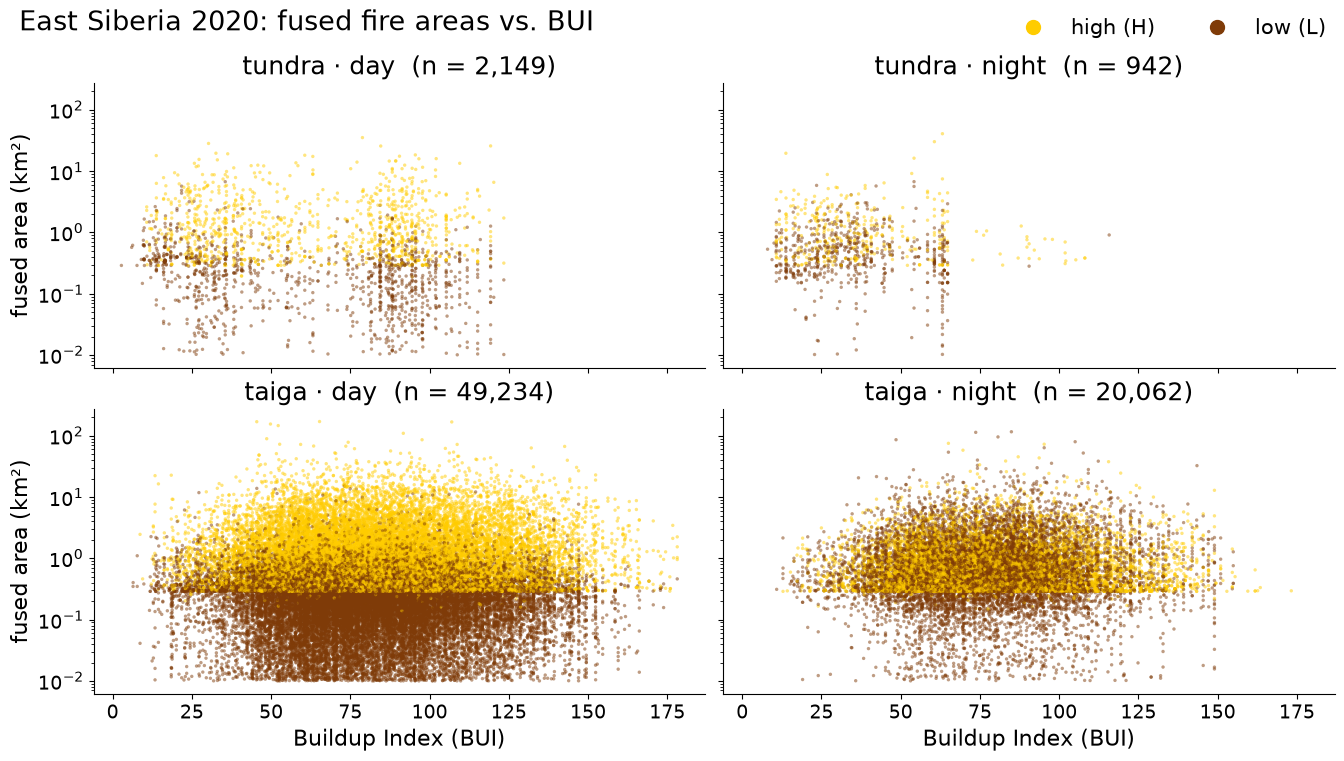

In [3]:
fig = plot_slide_grid(es, "bui", "area_km2", rows="biome", cols="Period", logy=True,
                      title="East Siberia 2020: fused fire areas vs. BUI")
save(fig, "eastsiberia_2020", "bui_area")

In [4]:
fig = plot_slide_grid(es, "date", "bui", rows="biome", cols="Period",
                      title="East Siberia 2020: BUI at fused fire areas through the season")
save(fig, "eastsiberia_2020", "date_bui")

## Alaska boreal 2022

In [5]:
ak = prepare("AK_boreal_2022", 2022)
ak.groupby(["Period", "Class"])[["bui", "dmc", "isi", "dc", "area_km2"]].median().round(1)

AK_boreal_2022: 26,860 fused areas, 1,167 below 0.01 km² dropped, 147 without BUI


bui   dmc  isi     dc  area_km2
Period Class                                  
day    H      75.1  53.8  5.5  318.6       0.8
       L      67.6  48.0  5.3  296.2       0.3
night  H      69.9  50.5  6.1  289.7       0.6
       L      63.9  45.6  6.0  271.4       0.5

In [6]:
fig = plot_slide_grid(ak, "bui", "area_km2", cols="Period", logy=True,
                      title="Alaska boreal 2022: fused fire areas vs. BUI")
save(fig, "AK_boreal_2022", "bui_area")

In [7]:
fig = plot_slide_grid(ak, "date", "bui", cols="Period",
                      title="Alaska boreal 2022: BUI at fused fire areas through the season")
save(fig, "AK_boreal_2022", "date_bui")

## Detections (points) vs. BUI

Here every detected pixel gets the BUI of its nearest grid cell. A pixels count as H (as in the
fused layer). Histograms are normalized per class; dashed lines are medians. Pixels are not
independent samples: neighboring pixels and repeated overpasses share one grid cell and day.
Day/night is the `Period` column (local solar time), as for the fused areas.

The tables are saved as `output/<run>/points_fwi.parquet`.

In [8]:
def prepare_points(run: str, year: int) -> pd.DataFrame:
    """Load a run's detections, sample the fire weather indices, save the table."""
    points = load_points(OUTPUT_ROOT / run / "gpkg")
    points = points.assign(lon=points["LON"], lat=points["LAT"],
                           Class=points["Type"].replace({"A": "H"}))
    table = sample_nearest(points, AUX_DIR / f"arcticfire_{year}.nc")
    table.to_parquet(OUTPUT_ROOT / run / "points_fwi.parquet")
    print(f"{run}: {len(table):,} detections, {table['bui'].isna().sum()} without BUI")
    return table

In [9]:
es_pts = prepare_points("eastsiberia_2020", 2020)
es_pts["biome"] = es_pts["aoi_id"].map(biome)
es_pts.groupby(["biome", "Period", "Class"])["bui"].describe()[["count", "25%", "50%", "75%"]].round(1)

eastsiberia_2020: 398,772 detections, 0 without BUI


count   25%   50%    75%
biome  Period Class                             
taiga  day    H      216283.0  64.6  83.8  104.8
              L       67052.0  62.3  79.0   97.5
       night  H       36225.0  63.3  77.9   95.3
              L       61892.0  64.7  80.1   94.3
tundra day    H       11488.0  35.9  78.8   91.6
              L        2498.0  29.6  70.9   88.5
       night  H        1948.0  23.8  38.5   60.6
              L        1386.0  24.1  34.4   50.6

In [10]:
fig = plot_slide_hist(es_pts, "bui", rows="biome", cols="Period",
                      title="East Siberia 2020: BUI at detected fire pixels")
save(fig, "eastsiberia_2020", "bui_hist_points")

In [11]:
ak_pts = prepare_points("AK_boreal_2022", 2022)
ak_pts.groupby(["Period", "Class"])["bui"].describe()[["count", "25%", "50%", "75%"]].round(1)

AK_boreal_2022: 124,155 detections, 295 without BUI


count   25%   50%   75%
Period Class                           
day    H      62127.0  59.1  76.3  92.7
       L      34067.0  45.5  66.9  91.1
night  H      13189.0  56.8  70.8  86.3
       L      14477.0  52.9  64.0  78.4

In [12]:
fig = plot_slide_hist(ak_pts, "bui", cols="Period",
                      title="Alaska boreal 2022: BUI at detected fire pixels")
save(fig, "AK_boreal_2022", "bui_hist_points")